# Imbalance Bars as Stopping Times

The tick rule assigns a direction to each price record, then forms signed tick, volume, or dollar contributions:

$$
b_i=\begin{cases}b_{i-1},&\Delta p_i=0,\\ \operatorname{sign}(\Delta p_i),&\Delta p_i\neq0,\end{cases}
\qquad x_i\in\{b_i,b_iv_i,b_ip_iv_i\}.
$$

Here, $b_i$ is the assigned direction; $\Delta p_i=p_i-p_{i-1}$ is the price change; $b_{i-1}$ carries direction through a zero change. $\operatorname{sign}$ returns the sign of a nonzero change; $x_i$ is the chosen signed contribution; $v_i$ is volume; $p_i$ is price.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=10080)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.data.structures.imbalance_bars import ExpectedImbalanceBars, FixedImbalanceBars
from RiskLabAI.utils.constants import CUMULATIVE_THETA, CUMULATIVE_TICKS, EXPECTED_IMBALANCE, EXPECTED_TICKS_NUMBER
FIGURES = ROOT / 'outputs' / 'figures' / '05_event_based_financial_time'
TABLES = ROOT / 'outputs' / 'tables' / '05_event_based_financial_time'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})
BAR_COLUMNS = ['Time', 'Last record', 'Open', 'High', 'Low', 'Close', 'Volume', 'Buy volume', 'Sell volume', 'Records', 'Dollar value', 'Rule level']

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def bar_frame(rows):
    frame = pd.DataFrame(rows, columns=BAR_COLUMNS)
    if not frame.empty:
        frame['Time'] = pd.to_datetime(frame['Time'])
    return frame
raw = raw.sort_values('time').dropna(subset=['time', 'close', 'volume']).reset_index(drop=True)
observations = list(raw[['time', 'close', 'volume']].itertuples(index=False, name=None))
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## The Tick Rule

Cumulative imbalance is the running sum of signed contributions through record $n.$:

$$
\theta_n=\sum_{i=1}^{n}x_i.
$$

Here, $\theta_n$ is cumulative imbalance; $x_i$ is the signed contribution from record $i$; $i$ labels records; $n$ is the current record count.

In [2]:
example_prices = np.array([100.0, 101.0, 101.0, 100.0, 100.0, 102.0, 101.0, 101.0])
example_moves = np.diff(example_prices, prepend=example_prices[0])
example_signs = np.zeros(example_prices.size, dtype=int)
prior_sign = 0
for position, move in enumerate(example_moves):
    if move != 0.0:
        prior_sign = int(np.sign(move))
    example_signs[position] = prior_sign
tick_rule_example = pd.DataFrame({
    "Record": np.arange(1, example_prices.size + 1),
    "Price": example_prices,
    "Price change": example_moves,
    "Carried sign": example_signs,
    "Cumulative imbalance": np.cumsum(example_signs),
})
save_table(tick_rule_example, "tick_rule_example", "The tick rule carries the last nonzero sign across an unchanged price.", "tab:tick-rule-example", fit=False)
display(tick_rule_example)

,Record,Price,Price change,Carried sign,Cumulative imbalance
0,1,100,0,0,0
1,2,101,1,1,1
2,3,101,0,1,2
3,4,100,-1,-1,1
4,5,100,0,-1,0
5,6,102,2,1,1
6,7,101,-1,-1,0
7,8,101,0,-1,-1


## First Crossing

The bar closes at the first record where absolute cumulative imbalance reaches its expected scale:

$$
\tau=\inf\left\{n\geq1:|\theta_n|\geq \widehat T\,|\widehat\mu_x|\right\}.
$$

Here, $\tau$ is the closing record; $n$ is a candidate record count; $\theta_n$ is cumulative imbalance. $\widehat T$ is expected bar length; $\widehat\mu_x$ is expected signed contribution per record; $\inf$ selects the first crossing.

Recent signed contributions receive more weight when estimating their current mean:

$$
\widehat\mu_{x,t}=\frac{x_t+q x_{t-1}+\cdots+q^t x_0}{1+q+\cdots+q^t},\qquad
q=1-\frac{2}{w+1}.
$$

Here, $\widehat\mu_{x,t}$ is the weighted mean at time $t$; $x_t,\ldots,x_0$ are present and past contributions. $q\in(0,1)$ is the weight decay factor; $w$ is the chosen span; $q^j$ is the weight on a contribution $j$ steps old.

In [3]:
fixed_rule = FixedImbalanceBars(
    "tick_imbalance",
    initial_estimate_of_expected_n_ticks_in_bar=60,
    window_size_for_expected_imbalance_estimation=120,
    analyse_thresholds=True,
)
expected_rule = ExpectedImbalanceBars(
    "tick_imbalance",
    window_size_for_expected_n_ticks_estimation=20,
    initial_estimate_of_expected_n_ticks_in_bar=60,
    window_size_for_expected_imbalance_estimation=240,
    expected_ticks_number_bounds=(20, 180),
    analyse_thresholds=True,
)
fixed_bars = bar_frame(fixed_rule.construct_bars_from_data(observations))
expected_bars = bar_frame(expected_rule.construct_bars_from_data(observations))
fixed_history = pd.DataFrame(fixed_rule.analyse_thresholds)
expected_history = pd.DataFrame(expected_rule.analyse_thresholds)

imbalance_bar_summary = pd.DataFrame([
    {
        "Rule": "Fixed expected length",
        "Complete bars": len(fixed_bars),
        "Smallest record count": fixed_bars["Records"].min(),
        "Middle record count": fixed_bars["Records"].median(),
        "Largest record count": fixed_bars["Records"].max(),
        "Middle rule level": fixed_bars["Rule level"].median(),
    },
    {
        "Rule": "Updated expected length",
        "Complete bars": len(expected_bars),
        "Smallest record count": expected_bars["Records"].min(),
        "Middle record count": expected_bars["Records"].median(),
        "Largest record count": expected_bars["Records"].max(),
        "Middle rule level": expected_bars["Rule level"].median(),
    },
])
save_table(imbalance_bar_summary, "imbalance_bar_summary", "Tick-imbalance bars formed from the one-week illustration.", "tab:imbalance-bar-summary")
display(imbalance_bar_summary.round(4))

,Rule,Complete bars,Smallest record count,Middle record count,Largest record count,Middle rule level
0,Fixed expected length,158,1,23,578,5.0458
1,Updated expected length,26,8,192,1881,13.3508


In [4]:
close_positions = fixed_bars["Last record"].astype(int).to_numpy() - 1
close_crossings = []
previous_steps_below = []
gaps = []
bar_start = 0
for close_position in close_positions:
    row = fixed_history.iloc[close_position]
    boundary = row[EXPECTED_TICKS_NUMBER] * abs(row[EXPECTED_IMBALANCE])
    close_crossings.append(abs(row[CUMULATIVE_THETA]) >= boundary)
    if close_position > bar_start:
        prior = fixed_history.iloc[close_position - 1]
        prior_boundary = prior[EXPECTED_TICKS_NUMBER] * abs(prior[EXPECTED_IMBALANCE])
        previous_steps_below.append(abs(prior[CUMULATIVE_THETA]) < prior_boundary)
        gaps.append(prior_boundary - abs(prior[CUMULATIVE_THETA]))
    bar_start = close_position + 1

stopping_check = pd.DataFrame({
    "Check": ["Completed bars cross their rule", "Immediately preceding records remain below the rule", "Smallest preceding gap"],
    "Result": [f"{sum(close_crossings)} of {len(close_crossings)}", f"{sum(previous_steps_below)} of {len(previous_steps_below)}", f"{min(gaps):.6f}"],
})
save_table(stopping_check, "imbalance_stopping_check", "Checks of the first-crossing rule for fixed tick-imbalance bars.", "tab:imbalance-stopping-check", fit=False)
display(stopping_check)

,Check,Result
0,Completed bars cross their rule,158 of 158
1,Immediately preceding records remain below the...,138 of 138
2,Smallest preceding gap,0.017148


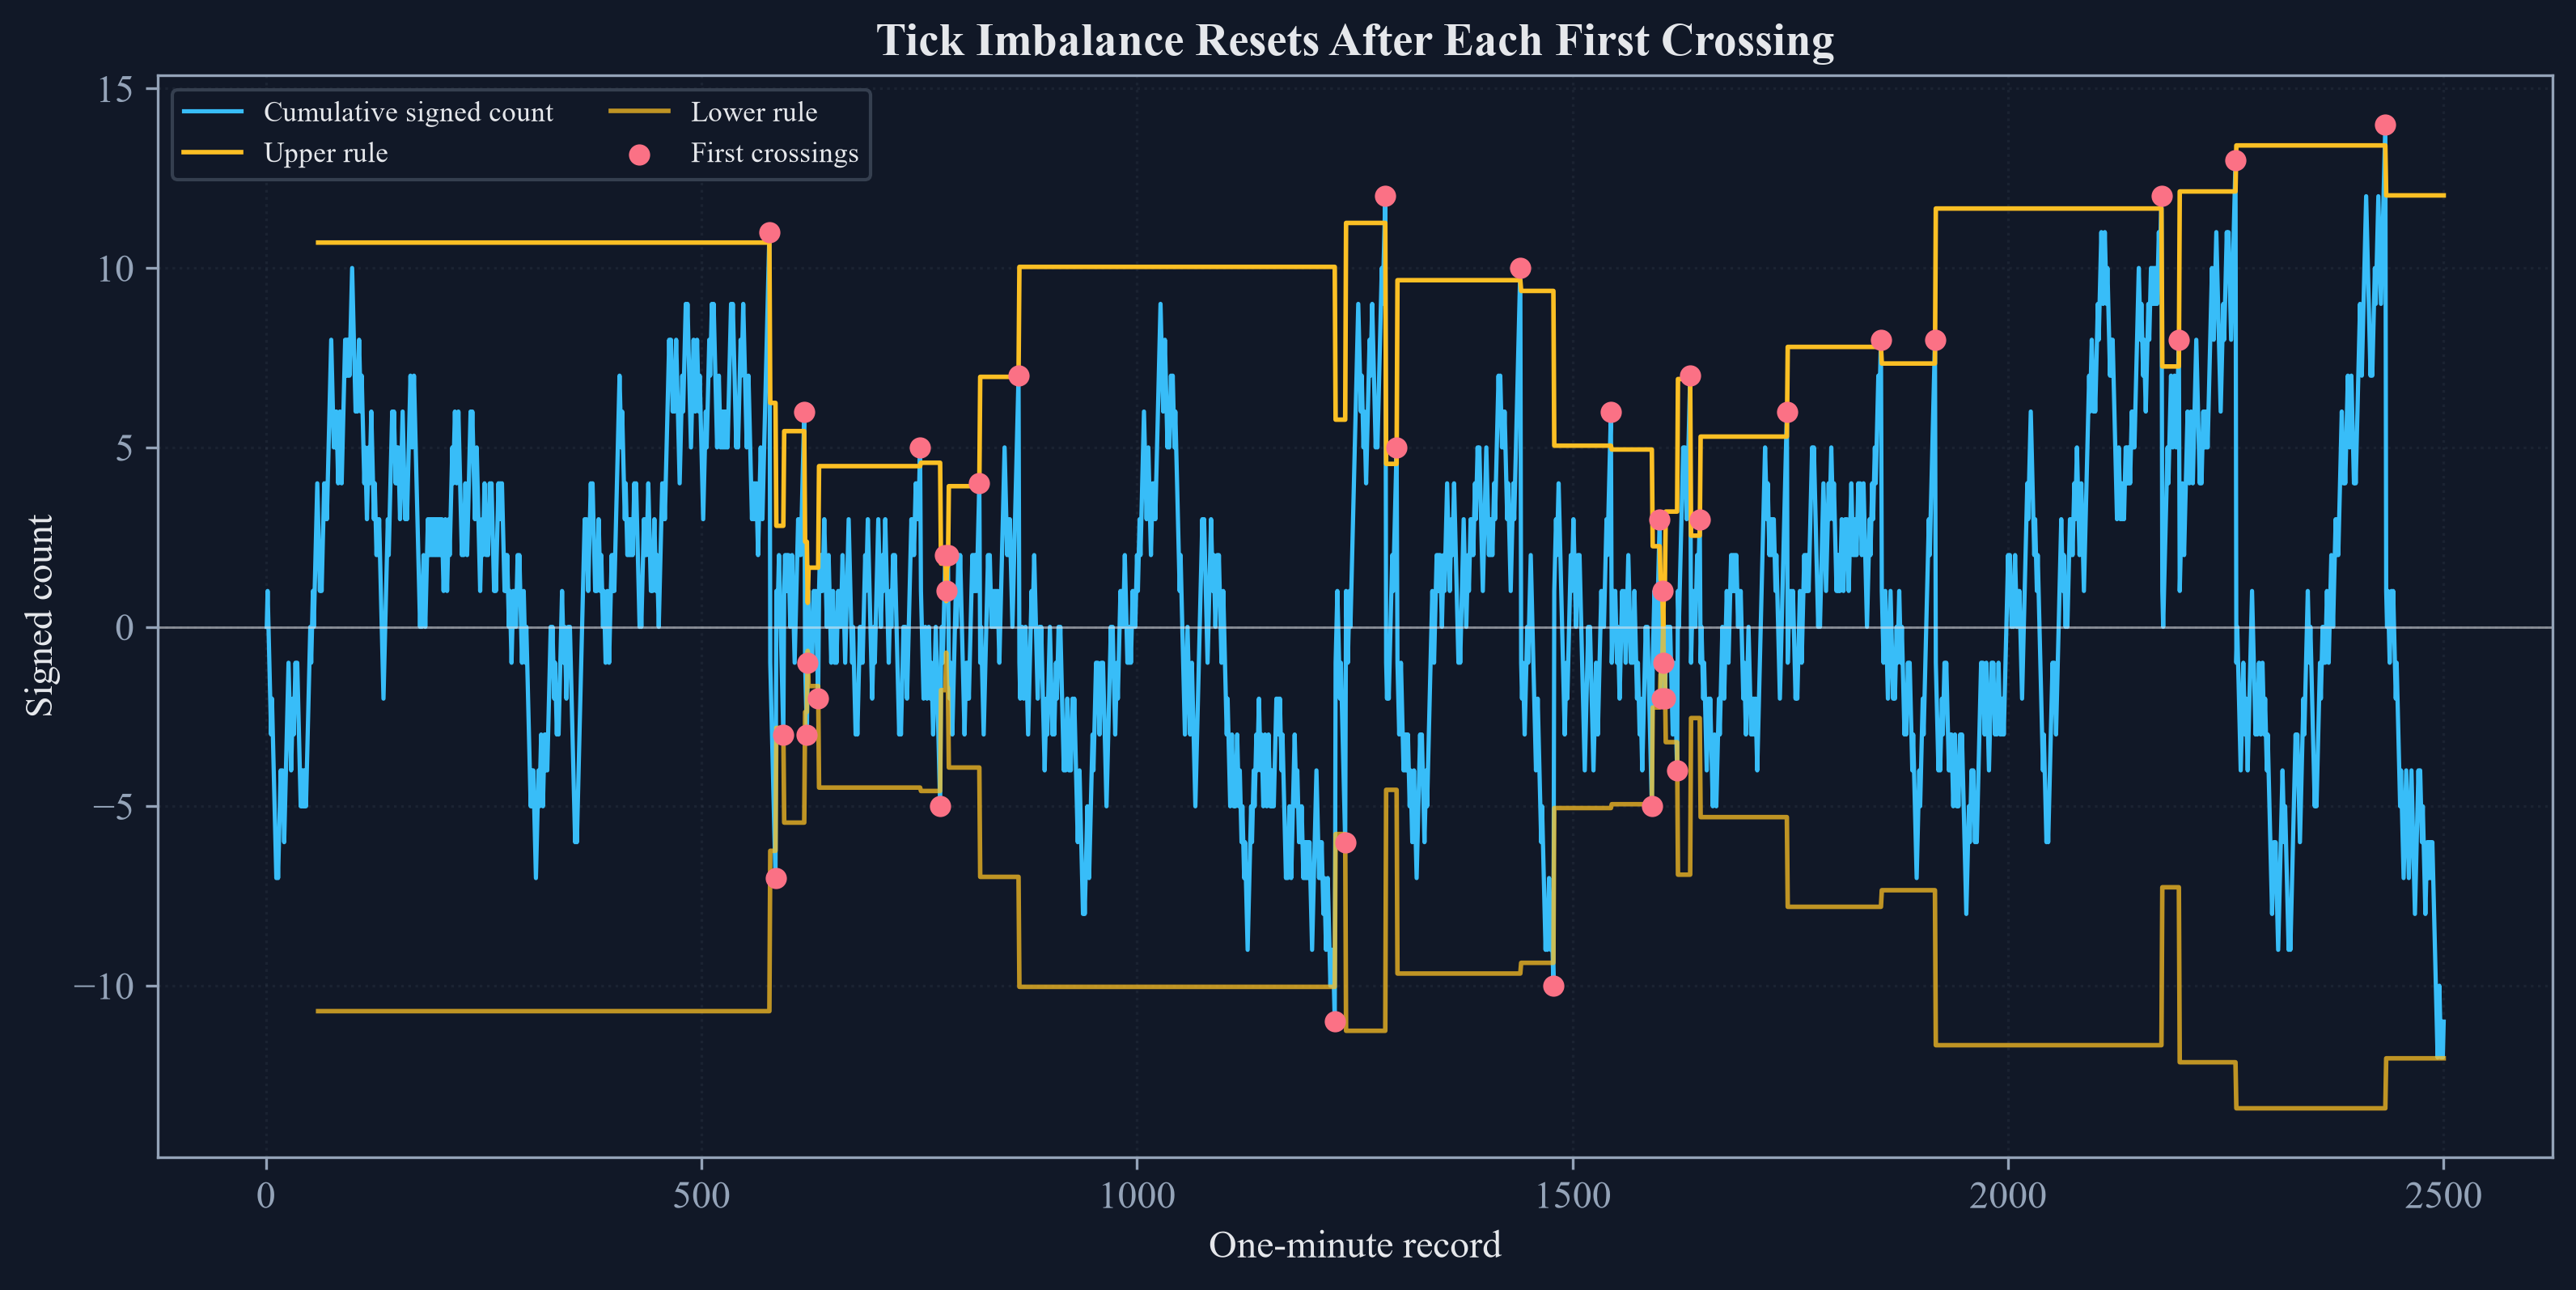

In [5]:
view = fixed_history.iloc[:2500].copy()
view_boundary = view[EXPECTED_TICKS_NUMBER] * view[EXPECTED_IMBALANCE].abs()
visible_closes = close_positions[close_positions < len(view)]
figure, axis = plt.subplots(figsize=(10.5, 5.2), constrained_layout=True)
axis.plot(view.index + 1, view[CUMULATIVE_THETA], color=palette["cyan"], linewidth=1.25, label="Cumulative signed count")
axis.plot(view.index + 1, view_boundary, color=palette["amber"], linewidth=1.35, label="Upper rule")
axis.plot(view.index + 1, -view_boundary, color=palette["amber"], linewidth=1.35, alpha=0.75, label="Lower rule")
axis.scatter(visible_closes + 1, fixed_history.iloc[visible_closes][CUMULATIVE_THETA], color=palette["rose"], s=28, zorder=4, label="First crossings")
axis.axhline(0.0, color=palette["text"], linewidth=0.7, alpha=0.55)
axis.set_xlabel("One-minute record")
axis.set_ylabel("Signed count")
axis.set_title("Tick Imbalance Resets After Each First Crossing")
axis.grid(True, alpha=0.28)
axis.legend(fontsize=8.5, ncol=2)
figure.savefig(FIGURES / "imbalance_first_crossings.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "imbalance_first_crossings.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "imbalance_first_crossings.png")))
plt.close(figure)

## Updating expected bar length

Expected bar length is either held at its starting value or updated from earlier observed bar lengths within chosen bounds:

$$
\widehat T_k^{\mathrm{fixed}}=T_0,\qquad
\widehat T_k^{\mathrm{updated}}=\operatorname{clip}\!\left(\operatorname{EWMA}(T_1,\ldots,T_{k-1}),T_{\min},T_{\max}\right).
$$

Here, $\widehat T_k$ is expected length for bar $k$; $T_0$ is the fixed starting length; $T_1,\ldots,T_{k-1}$ are earlier lengths. $\operatorname{EWMA}$ is an exponentially weighted mean; $T_{\min}$ and $T_{\max}$ are lower and upper bounds; $\operatorname{clip}$ enforces them.

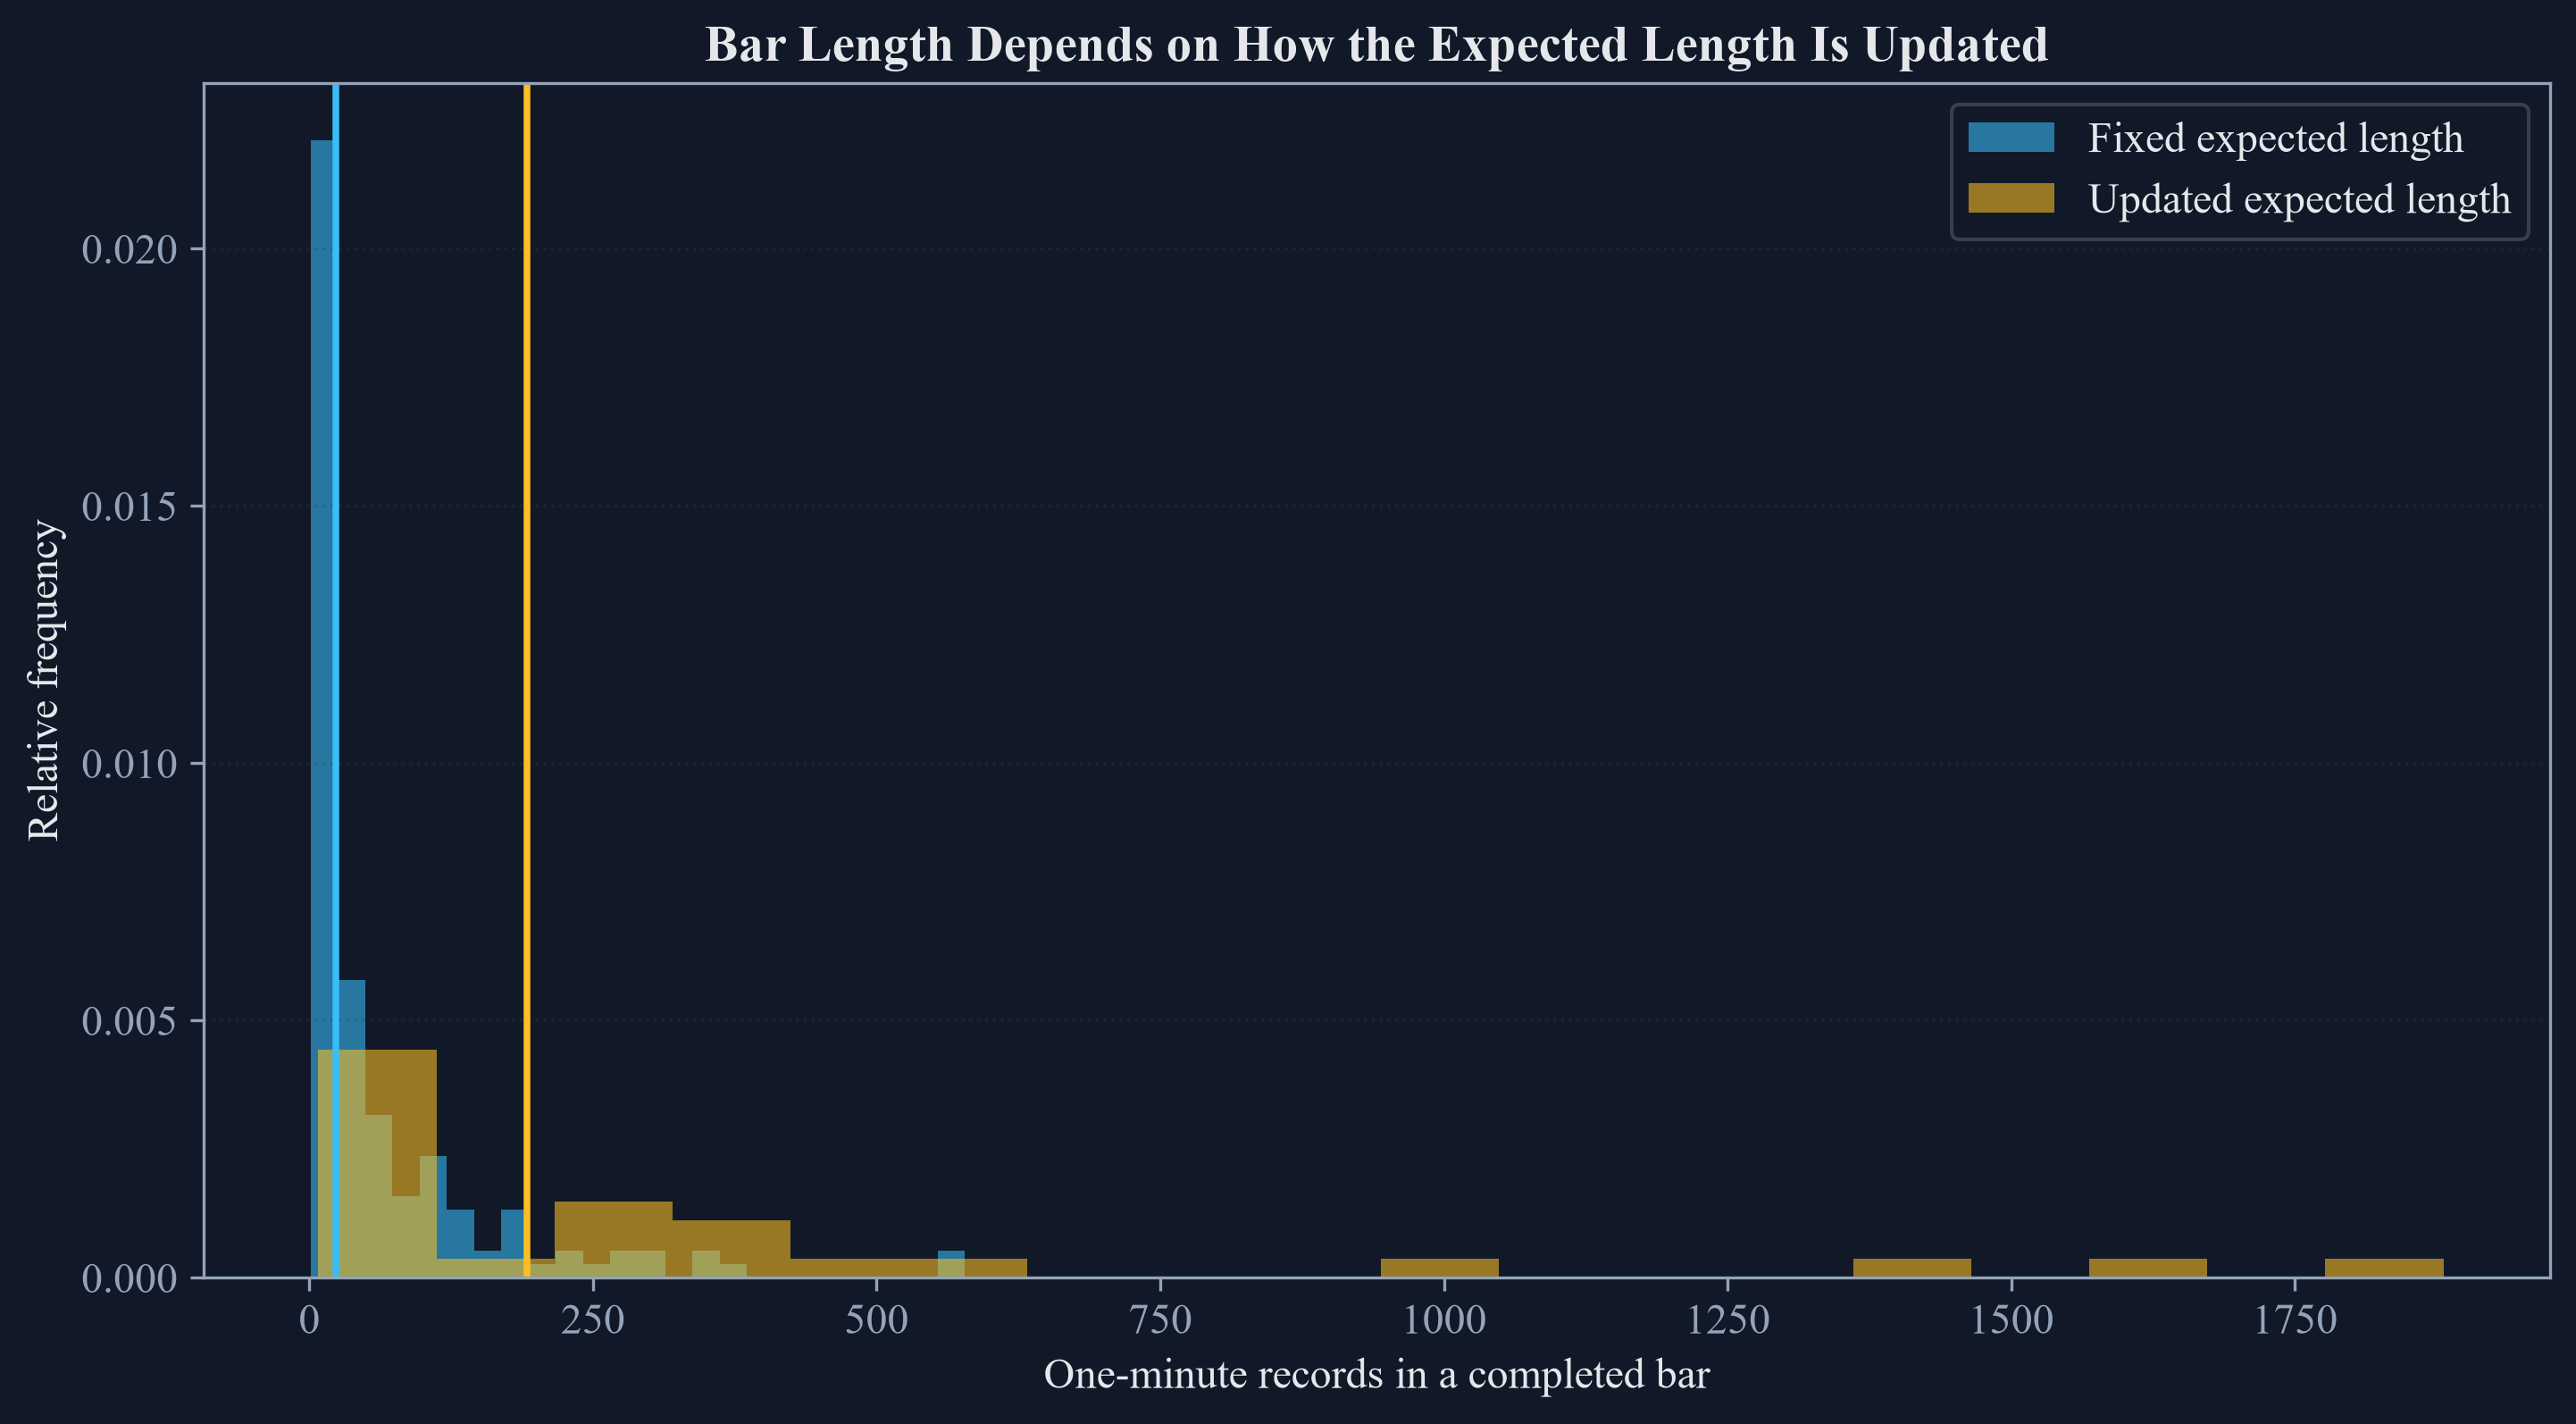

In [6]:
figure, axis = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)
axis.hist(fixed_bars["Records"], bins=24, color=palette["cyan"], alpha=0.58, density=True, label="Fixed expected length")
axis.hist(expected_bars["Records"], bins=18, color=palette["amber"], alpha=0.58, density=True, label="Updated expected length")
axis.axvline(fixed_bars["Records"].median(), color=palette["cyan"], linewidth=1.8)
axis.axvline(expected_bars["Records"].median(), color=palette["amber"], linewidth=1.8)
axis.set_xlabel("One-minute records in a completed bar")
axis.set_ylabel("Relative frequency")
axis.set_title("Bar Length Depends on How the Expected Length Is Updated")
axis.grid(True, axis="y", alpha=0.28)
axis.legend()
figure.savefig(FIGURES / "imbalance_bar_lengths.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "imbalance_bar_lengths.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "imbalance_bar_lengths.png")))
plt.close(figure)

## Tests

In [7]:
assert np.array_equal(example_signs, np.array([0, 1, 1, -1, -1, 1, -1, -1]))
assert np.array_equal(tick_rule_example["Cumulative imbalance"].to_numpy(), np.array([0, 1, 2, 1, 0, 1, 0, -1]))
assert len(fixed_history) == len(raw)
assert len(expected_history) == len(raw)
assert len(fixed_bars) == 158
assert len(expected_bars) == 26
assert all(close_crossings)
assert all(previous_steps_below)
assert min(gaps) > 0.0
assert np.all(np.diff(close_positions) > 0)
assert fixed_bars["Last record"].max() <= len(raw)
assert expected_bars["Last record"].max() <= len(raw)
assert fixed_bars["Records"].min() >= 1
assert expected_bars["Records"].min() >= 1
assert fixed_bars["Rule level"].gt(0.0).all()
assert expected_bars["Rule level"].gt(0.0).all()
assert fixed_history[EXPECTED_TICKS_NUMBER].dropna().eq(60.0).all()
assert expected_history[EXPECTED_TICKS_NUMBER].dropna().between(20.0, 180.0).all()
assert (FIGURES / "imbalance_first_crossings.pdf").exists()
assert (FIGURES / "imbalance_bar_lengths.pdf").exists()
assert (TABLES / "tick_rule_example.tex").exists()
assert (TABLES / "imbalance_bar_summary.tex").exists()
assert (TABLES / "imbalance_stopping_check.tex").exists()